# Exploratory review of the synthetic procurement book

This notebook reads `data/raw`. Every row is synthetic. The charts in `screenshots/` are matplotlib previews written by the pipeline, not Power BI pages.

In [1]:
import sys
from pathlib import Path
root = Path.cwd().resolve()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))


In [2]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from src.utils.config import load_config
from src.utils.frames import read_operational_tables
from src.data_quality.validate import validate_tables

config = load_config()
root = Path(config['_project_root'])
tables = read_operational_tables(root / 'data' / 'raw')
shapes = pd.DataFrame({
    'rows': {name: len(frame) for name, frame in tables.items()},
    'columns': {name: frame.shape[1] for name, frame in tables.items()},
})
shapes

,rows,columns
employees,120,11
vendors,60,11
purchase_orders,850,10
invoices,1500,18
payments,1400,9
employee_expenses,900,10
approval_records,1785,8


Missing values are reported and kept. The quality module does not drop them.

In [3]:
missing = []
for name, frame in tables.items():
    counts = frame.isna().sum()
    counts = counts[counts > 0]
    for column, count in counts.items():
        missing.append({'table': name, 'column': column, 'missing_rows': int(count)})
pd.DataFrame(missing)

,table,column,missing_rows
0,employees,email,4
1,vendors,city,3


In [4]:
summary, failures = validate_tables(tables, config)
print('checks', len(summary), 'passed', int(summary['passed'].sum()), 'pass_rate', round(float(summary['passed'].mean()), 4))
failures.groupby('check_id').size().sort_values(ascending=False)

checks 30 passed 15 pass_rate 0.5


check_id
NEGATIVE_AMOUNT             15
INVOICE_MATH_MISMATCH       13
INVALID_CATEGORY             6
OUT_OF_RANGE_DATE            6
ORPHAN_PO_REFERENCE          6
NULL_EMPLOYEE_EMAIL          4
DUPLICATE_BANK_HASH          4
INVALID_DATE_SEQUENCE        4
ORPHAN_INVOICE_REFERENCE     3
NULL_VENDOR_CITY             3
TRANSACTION_BEFORE_HIRE      3
DUPLICATE_PRIMARY_KEY        2
dtype: int64

Invoice totals below are the raw file, including planted negative and duplicate-key rows. Spend charts in the pipeline use positive totals.

In [5]:
invoices = tables['invoices'].copy()
invoices['total_amount_inr'] = pd.to_numeric(invoices['total_amount_inr'], errors='coerce')
invoices['total_amount_inr'].describe()

count      1500.000000
mean      43952.957240
std       61552.521349
min       -9558.000000
25%        9558.000000
50%       19799.620000
75%       48000.040000
max      407341.290000
Name: total_amount_inr, dtype: float64

In [6]:
orders = tables['purchase_orders']
department = orders.groupby('department')['po_amount_inr'].sum().sort_values(ascending=False)
department

department
Procurement               15352637.49
Facilities                11250741.54
Operations                 9913043.35
Finance                    8205197.78
Human Resources            7811333.81
Information Technology     7400620.69
Legal                      5510529.38
Marketing                  4547870.52
Name: po_amount_inr, dtype: float64

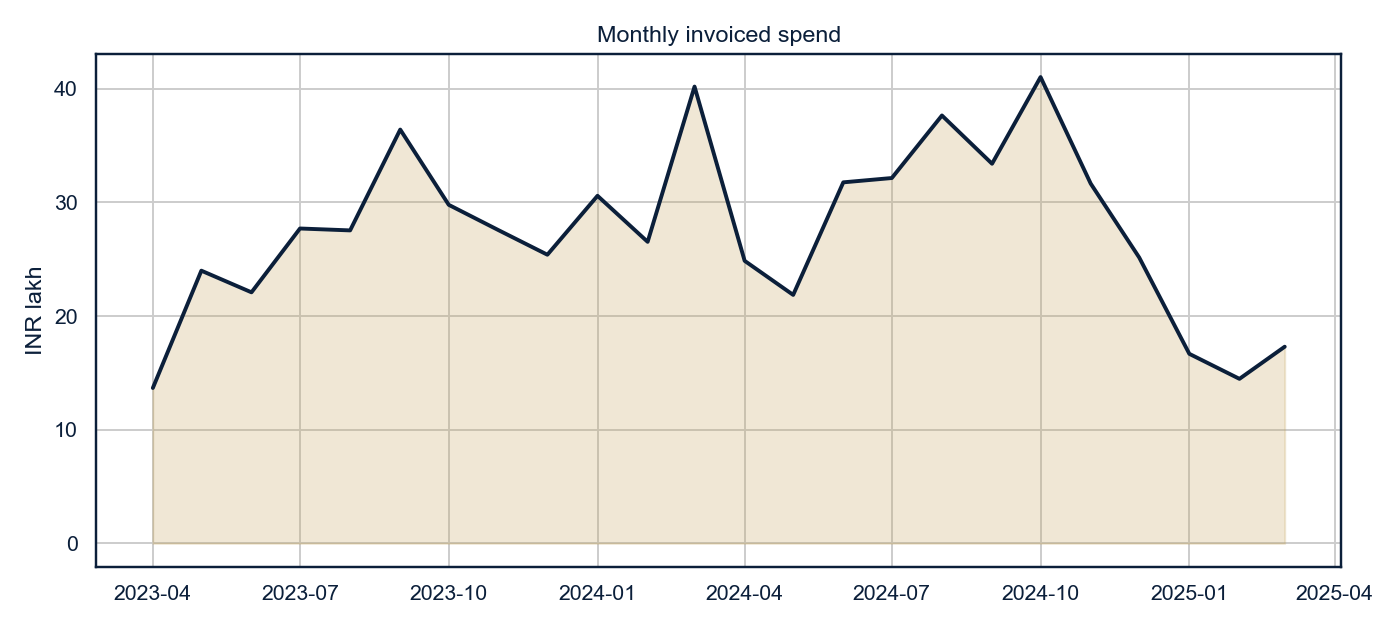

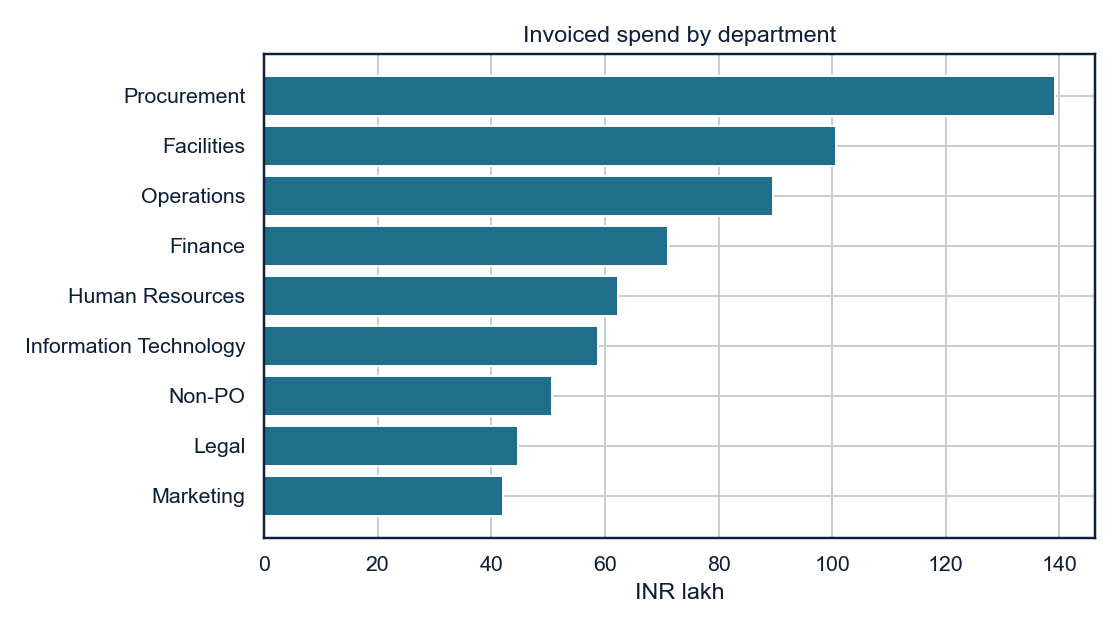

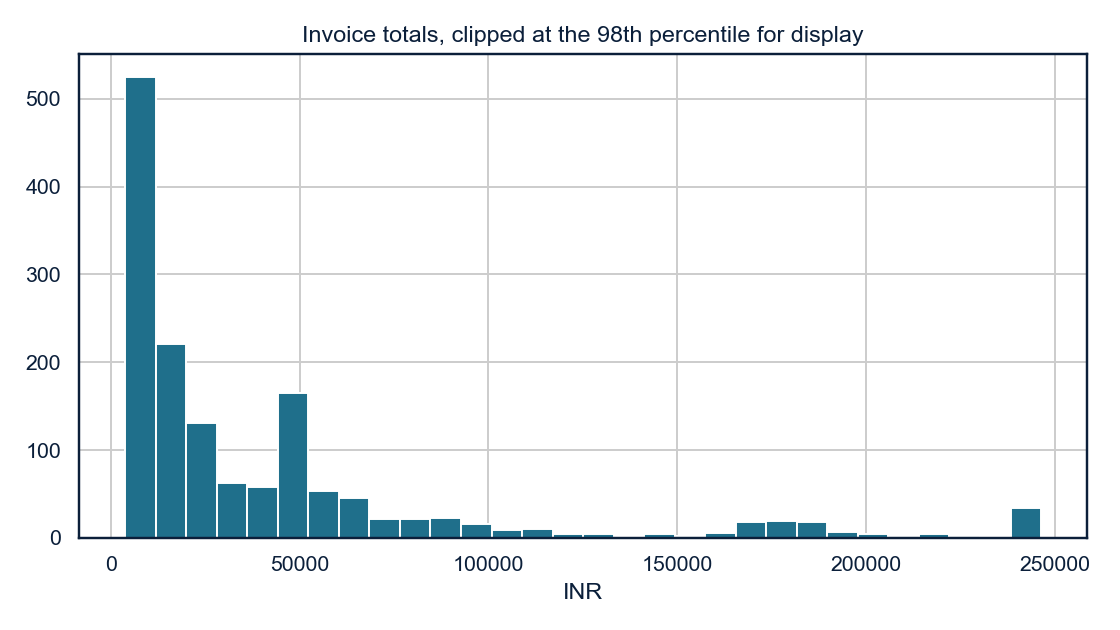

In [7]:
for image_name in [
    '01_monthly_spend.png',
    '02_department_spend.png',
    '07_invoice_amount_distribution.png',
]:
    display(Image(filename=str(root / 'screenshots' / image_name)))